In [1]:
import sys; print(sys.executable)

d:\Portfolio_projects_2026\WBR_AWS_Hackathon\team-s04-wbr-agent\.venv\Scripts\python.exe


In [2]:
import duckdb
from pathlib import Path

ROOT = Path("..")                    # notebook is in notebooks/, project root is one level up
RAW = ROOT / "data" / "raw"          # original Olist CSVs
DB_PATH = ROOT / "data" / "olist.duckdb"   # the one database the notebook and the tools share

con = duckdb.connect(str(DB_PATH))
con.sql("SHOW TABLES").show()

┌─────────────────────────┐
│          name           │
│         varchar         │
├─────────────────────────┤
│ category_translation    │
│ customers               │
│ order_facts             │
│ order_items             │
│ orders                  │
│ products                │
│ reviews                 │
│ weekly_category_metrics │
│ weekly_metrics          │
└─────────────────────────┘



In [3]:
#exploring "orders" table
con.sql("DESCRIBE orders").show()

┌───────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│          column_name          │ column_type │  null   │   key   │ default │  extra  │
│            varchar            │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ order_id                      │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_id                   │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_status                  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_purchase_timestamp      │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ order_approved_at             │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ order_delivered_carrier_date  │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ order_delivered_customer_date │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ order_estimated_delivery_date 

checking dtypes of all columns in the orders table . do all date columns is in timestamp type?

In [4]:
con.sql("SELECT * FROM orders LIMIT 5").show()

┌──────────────────────────────────┬──────────────────────────────────┬──────────────┬──────────────────────────┬─────────────────────┬──────────────────────────────┬───────────────────────────────┬───────────────────────────────┐
│             order_id             │           customer_id            │ order_status │ order_purchase_timestamp │  order_approved_at  │ order_delivered_carrier_date │ order_delivered_customer_date │ order_estimated_delivery_date │
│             varchar              │             varchar              │   varchar    │        timestamp         │      timestamp      │          timestamp           │           timestamp           │           timestamp           │
├──────────────────────────────────┼──────────────────────────────────┼──────────────┼──────────────────────────┼─────────────────────┼──────────────────────────────┼───────────────────────────────┼───────────────────────────────┤
│ e481f51cbdc54678b7cc49136f2d6af7 │ 9ef432eb6251297304e76186b10a928d │ deli

Checking table "Oder_items"

In [5]:
con.sql("DESCRIBE order_items").show()

┌─────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│     column_name     │ column_type │  null   │   key   │ default │  extra  │
│       varchar       │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ order_id            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_item_id       │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ product_id          │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ seller_id           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ shipping_limit_date │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ price               │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
│ freight_value       │ DOUBLE      │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



In [6]:
con.sql("SELECT * FROM order_items LIMIT 5").show()

┌──────────────────────────────────┬───────────────┬──────────────────────────────────┬──────────────────────────────────┬─────────────────────┬────────┬───────────────┐
│             order_id             │ order_item_id │            product_id            │            seller_id             │ shipping_limit_date │ price  │ freight_value │
│             varchar              │     int64     │             varchar              │             varchar              │      timestamp      │ double │    double     │
├──────────────────────────────────┼───────────────┼──────────────────────────────────┼──────────────────────────────────┼─────────────────────┼────────┼───────────────┤
│ 00010242fe8c5a6d1ba2dd792cb16214 │             1 │ 4244733e06e7ecb4970a6e2683c13e61 │ 48436dade18ac8b2bce089ec2a041202 │ 2017-09-19 09:45:35 │   58.9 │         13.29 │
│ 00018f77f2f0320c557190d7a144bdd3 │             1 │ e5f2d52b802189ee658865ca93d83a8f │ dd7ddc04e1b6c2c614352b383efe2d36 │ 2017-05-03 11:05:13 │  239.

In [7]:
con.sql("DESCRIBE reviews").show()

┌─────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│       column_name       │ column_type │  null   │   key   │ default │  extra  │
│         varchar         │   varchar   │ varchar │ varchar │ varchar │ varchar │
├─────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ review_id               │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ order_id                │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ review_score            │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ review_comment_title    │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ review_comment_message  │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ review_creation_date    │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
│ review_answer_timestamp │ TIMESTAMP   │ YES     │ NULL    │ NULL    │ NULL    │
└─────────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



In this review table , the review comments is in portuguese. we are only considering review score column for this task

In [8]:
con.sql("SELECT * FROM reviews LIMIT 5").show()

┌──────────────────────────────────┬──────────────────────────────────┬──────────────┬──────────────────────┬──────────────────────────────────────────────────────────────────────────────────────────────────────┬──────────────────────┬─────────────────────────┐
│            review_id             │             order_id             │ review_score │ review_comment_title │                                        review_comment_message                                        │ review_creation_date │ review_answer_timestamp │
│             varchar              │             varchar              │    int64     │       varchar        │                                               varchar                                                │      timestamp       │        timestamp        │
├──────────────────────────────────┼──────────────────────────────────┼──────────────┼──────────────────────┼──────────────────────────────────────────────────────────────────────────────────────────────────────┼──

Finding: late delivery is strongly associated with lower review scores

In [9]:
con.sql("""
WITH order_review AS (
    -- one score per order (averages the few orders with multiple reviews)
    SELECT order_id, AVG(review_score) AS review_score
    FROM reviews
    GROUP BY order_id
),
delivered AS (
    -- delivered orders with both dates, flagged late or on time
    SELECT
        order_id,
        CAST(order_delivered_customer_date AS DATE)
            > CAST(order_estimated_delivery_date AS DATE) AS is_late
    FROM orders
    WHERE order_status = 'delivered'
      AND order_delivered_customer_date IS NOT NULL
      AND order_estimated_delivery_date IS NOT NULL
)
SELECT
    CASE WHEN d.is_late THEN 'late' ELSE 'on time' END AS delivery,
    COUNT(*) AS orders,
    ROUND(AVG(r.review_score), 2) AS avg_review,
    ROUND(100 * AVG(CASE WHEN r.review_score = 1 THEN 1 ELSE 0 END), 1) AS pct_1_star,
    ROUND(100 * AVG(CASE WHEN r.review_score >= 4 THEN 1 ELSE 0 END), 1) AS pct_4_5_star
FROM delivered d
JOIN order_review r USING (order_id)
GROUP BY 1
ORDER BY 1
""").show()

┌──────────┬────────┬────────────┬────────────┬──────────────┐
│ delivery │ orders │ avg_review │ pct_1_star │ pct_4_5_star │
│ varchar  │ int64  │   double   │   double   │    double    │
├──────────┼────────┼────────────┼────────────┼──────────────┤
│ late     │   6381 │       2.27 │       53.7 │         26.7 │
│ on time  │  89443 │       4.29 │        6.6 │         82.6 │
└──────────┴────────┴────────────┴────────────┴──────────────┘



Late orders score about 2 stars lower on average.
More than half of late orders receive 1 star, about 8 times the rate for on-time orders.
Late orders make up about 6.7% of delivered orders.

Why it matters: this supports using delivery data as evidence when the agent investigates review score changes.

Limitation: this shows association, not cause. Late orders may differ in other ways, such as size or destination. About 650 delivered orders were excluded because they lacked a delivery date or a review.

Qunatifyign the number of NUll values i nthis reviews table

In [10]:
con.sql("""
SELECT
    COUNT(*) AS total_reviews,
    COUNT(*) - COUNT(review_score) AS null_score,
    COUNT(*) - COUNT(review_comment_title) AS null_title,
    COUNT(*) - COUNT(review_comment_message) AS null_message
FROM reviews
""").show()

┌───────────────┬────────────┬────────────┬──────────────┐
│ total_reviews │ null_score │ null_title │ null_message │
│     int64     │   int64    │   int64    │    int64     │
├───────────────┼────────────┼────────────┼──────────────┤
│         99224 │          0 │      87656 │        58247 │
└───────────────┴────────────┴────────────┴──────────────┘



This is harmless because, comments are optional for customers adn this nULL carries usefull information itself

Checking Customers tables and the dtypes

In [11]:
con.sql("DESCRIBE customers").show()

┌──────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│       column_name        │ column_type │  null   │   key   │ default │  extra  │
│         varchar          │   varchar   │ varchar │ varchar │ varchar │ varchar │
├──────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ customer_id              │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_unique_id       │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_zip_code_prefix │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_city            │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ customer_state           │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└──────────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



In [12]:
con.sql("SELECT * FROM customers LIMIT 5").show()

┌──────────────────────────────────┬──────────────────────────────────┬──────────────────────────┬───────────────────────┬────────────────┐
│           customer_id            │        customer_unique_id        │ customer_zip_code_prefix │     customer_city     │ customer_state │
│             varchar              │             varchar              │         varchar          │        varchar        │    varchar     │
├──────────────────────────────────┼──────────────────────────────────┼──────────────────────────┼───────────────────────┼────────────────┤
│ 06b8999e2fba1a1fbc88172c00ba8bc7 │ 861eff4711a542e4b93843c6dd7febb0 │ 14409                    │ franca                │ SP             │
│ 18955e83d337fd6b2def6b18a428ac77 │ 290c77bc529b7ac935b93aa66c333dc3 │ 09790                    │ sao bernardo do campo │ SP             │
│ 4e7b3e00288586ebd08712fdd0374a03 │ 060e732b5b29e8181a18229c7b0b2b5e │ 01151                    │ sao paulo             │ SP             │
│ b2b6027bc5c5109e52

Mitigating small-sample problem by grouping the states based on the average number of orders. 

In [13]:
con.sql("""
SELECT MIN(order_purchase_timestamp) AS first_order,
       MAX(order_purchase_timestamp) AS last_order
FROM orders
""").show()

┌─────────────────────┬─────────────────────┐
│     first_order     │     last_order      │
│      timestamp      │      timestamp      │
├─────────────────────┼─────────────────────┤
│ 2016-09-04 21:15:19 │ 2018-10-17 17:30:18 │
└─────────────────────┴─────────────────────┘



In [15]:
pip install matplotlib

  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   --------------------------------- ------ 7.9/9.3 MB 34.7 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 34.2 MB/s eta 0:00:00
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 2.5/2.5 MB 35.3 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   ---------------------------------------- 7.2/7.2 MB 40.5 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


<Axes: title={'center': 'Orders per week'}, xlabel='week_start'>

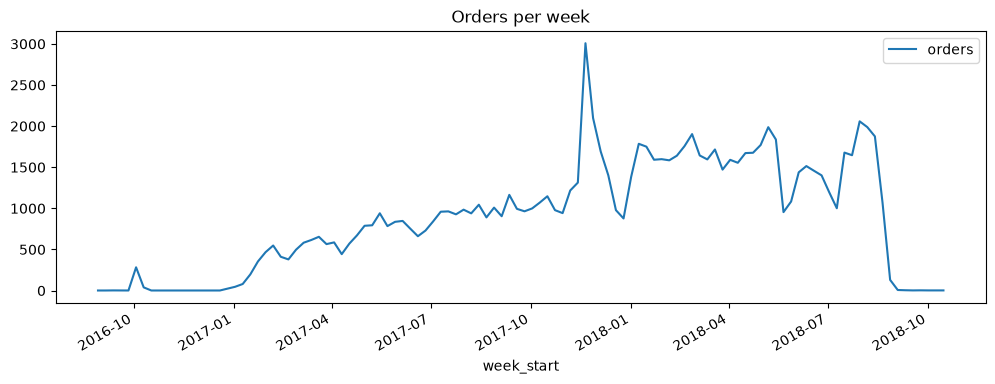

In [16]:
weekly_total = con.sql("""
SELECT date_trunc('week', order_purchase_timestamp) AS week_start,
       COUNT(*) AS orders
FROM orders
GROUP BY 1
ORDER BY 1
""").df()

weekly_total.plot(x="week_start", y="orders", figsize=(12, 4), title="Orders per week")

1. 2016 is unusable. Almost no orders, apart from one small blip in early October 2016, then nearly zero through December. Why exclude it: a handful of orders per week would make every metric jump randomly.

2. Early 2017 is a ramp-up. Orders climb from near zero in January to about 500 per week by February. These are real but small weeks, so the first few should be excluded too.

3. Steady growth from about February 2017 to August 2018. Roughly 500–1,000 orders per week in 2017, and 1,500–2,000 in 2018. This is your usable period.

4. A big spike in late November 2017 (about 3,000 orders). That week lines up with Black Friday. It's real demand, not a data error, so keep it. Just know the week after it will look like a big "drop" in comparison.

5. Dips in late December 2017 and mid-June 2018. The December dip fits the holidays. I don't know the cause of the June dip, so the agent should treat it carefully. It's a good real example of a change that may be "unexplained."

In [17]:
print(weekly_total[(weekly_total.week_start >= "2017-01-01") & (weekly_total.week_start < "2017-03-01")])
print(weekly_total.tail(12))

   week_start  orders
8  2017-01-02      46
9  2017-01-09      80
10 2017-01-16     197
11 2017-01-23     354
12 2017-01-30     467
13 2017-02-06     548
14 2017-02-13     411
15 2017-02-20     379
16 2017-02-27     497
    week_start  orders
89  2018-07-23    1646
90  2018-07-30    2058
91  2018-08-06    1988
92  2018-08-13    1875
93  2018-08-20    1071
94  2018-08-27     130
95  2018-09-03       7
96  2018-09-10       4
97  2018-09-17       2
98  2018-09-24       3
99  2018-10-01       2
100 2018-10-15       2


In [8]:
state_weekly = con.sql("""
WITH weekly AS (
    SELECT c.customer_state,
           date_trunc('week', o.order_purchase_timestamp) AS week_start,
           COUNT(*) AS orders
    FROM orders o
    JOIN customers c USING (customer_id)
    WHERE week_start BETWEEN DATE '2017-01-30' AND DATE '2018-08-13'
    GROUP BY 1, 2
)
SELECT customer_state,
       SUM(orders)     AS total_orders,
       MEDIAN(orders)  AS median_weekly,
       CASE WHEN MEDIAN(orders) >= 30 THEN 'own group' ELSE 'Other' END AS grouping
FROM weekly
GROUP BY 1
ORDER BY median_weekly DESC
""").df()

print(state_weekly)

   customer_state  total_orders  median_weekly   grouping
0              SP       40605.0          411.0  own group
1              RJ       12594.0          139.0  own group
2              MG       11368.0          123.0  own group
3              RS        5362.0           65.0  own group
4              PR        4918.0           54.0  own group
5              BA        3344.0           41.0  own group
6              SC        3573.0           41.0  own group
7              DF        2100.0           25.0      Other
8              GO        1984.0           24.0      Other
9              ES        2007.0           22.0      Other
10             PE        1633.0           19.0      Other
11             CE        1318.0           16.0      Other
12             PA         961.0           11.0      Other
13             MT         889.0           10.0      Other
14             MA         732.0            8.0      Other
15             MS         713.0            8.0      Other
16            

I grouped states using a minimum volume of 30 orders per week, confirmed by a natural break in the distribution, which kept 7 states covering 84% of orders and merged the long tail into 'Other.' Separately, when flagging changes, the agent compares each group's change to its normal variability, so borderline groups don't create false alarms.I used 30 as a minimum because the Central Limit Theorem makes the sampling distribution of the mean approximately normal at around that size. But for rare-event rates like late delivery, I required more events, since 30 orders at a 7% late rate gives only about 2 late orders.

In [19]:
con.sql("DESCRIBE products").show()

┌────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│        column_name         │ column_type │  null   │   key   │ default │  extra  │
│          varchar           │   varchar   │ varchar │ varchar │ varchar │ varchar │
├────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ product_id                 │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ product_category_name      │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ product_name_lenght        │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ product_description_lenght │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ product_photos_qty         │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ product_weight_g           │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ product_length_cm          │ BIGINT      │ YES     │ NULL    │ NULL    │ NULL    │
│ product_height_cm          │ BIGINT      │ YES     │ NULL    │ 

In [20]:
con.sql("""
SELECT COUNT(*) AS products,
       COUNT(*) - COUNT(product_category_name) AS missing_category,
       COUNT(DISTINCT product_category_name) AS categories
FROM products
""").show()

┌──────────┬──────────────────┬────────────┐
│ products │ missing_category │ categories │
│  int64   │      int64       │   int64    │
├──────────┼──────────────────┼────────────┤
│    32951 │              610 │         73 │
└──────────┴──────────────────┴────────────┘



In [21]:
con.sql("""
SELECT product_id,
       COALESCE(product_category_name, 'unknown') AS category_pt
FROM products
LIMIT 5
""").show()

┌──────────────────────────────────┬───────────────────────┐
│            product_id            │      category_pt      │
│             varchar              │        varchar        │
├──────────────────────────────────┼───────────────────────┤
│ 1e9e8ef04dbcff4541ed26657ea517e5 │ perfumaria            │
│ 3aa071139cb16b67ca9e5dea641aaa2f │ artes                 │
│ 96bd76ec8810374ed1b65e291975717f │ esporte_lazer         │
│ cef67bcfe19066a932b7673e239eb23d │ bebes                 │
│ 9dc1a7de274444849c219cff195d0b71 │ utilidades_domesticas │
└──────────────────────────────────┴───────────────────────┘



In [22]:
con.sql("""
SELECT
    p.product_category_name IS NULL AS missing_category,
    COUNT(*) AS items,
    ROUND(SUM(oi.price), 0) AS revenue
FROM order_items oi
JOIN products p USING (product_id)
GROUP BY 1
""").show()

┌──────────────────┬────────┬────────────┐
│ missing_category │ items  │  revenue   │
│     boolean      │ int64  │   double   │
├──────────────────┼────────┼────────────┤
│ true             │   1603 │   179535.0 │
│ false            │ 111047 │ 13412108.0 │
└──────────────────┴────────┴────────────┘



610 products (1.9% of products) have no category. They account for 1.4% of items sold and 1.3% of revenue. Labeled 'unknown' and included in 'Other'; not dropped, so revenue totals remain complete.

In [23]:
con.sql("DESCRIBE category_translation").show()

┌───────────────────────────────┬─────────────┬─────────┬─────────┬─────────┬─────────┐
│          column_name          │ column_type │  null   │   key   │ default │  extra  │
│            varchar            │   varchar   │ varchar │ varchar │ varchar │ varchar │
├───────────────────────────────┼─────────────┼─────────┼─────────┼─────────┼─────────┤
│ product_category_name         │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
│ product_category_name_english │ VARCHAR     │ YES     │ NULL    │ NULL    │ NULL    │
└───────────────────────────────┴─────────────┴─────────┴─────────┴─────────┴─────────┘



In [24]:
con.sql("SELECT * FROM category_translation LIMIT 5").show()

┌────────────────────────┬───────────────────────────────┐
│ product_category_name  │ product_category_name_english │
│        varchar         │            varchar            │
├────────────────────────┼───────────────────────────────┤
│ beleza_saude           │ health_beauty                 │
│ informatica_acessorios │ computers_accessories         │
│ automotivo             │ auto                          │
│ cama_mesa_banho        │ bed_bath_table                │
│ moveis_decoracao       │ furniture_decor               │
└────────────────────────┴───────────────────────────────┘



In [25]:
con.sql("""
SELECT DISTINCT p.product_category_name
FROM products p
LEFT JOIN category_translation t USING (product_category_name)
WHERE p.product_category_name IS NOT NULL
  AND t.product_category_name_english IS NULL
""").show()

┌───────────────────────────────────────────────┐
│             product_category_name             │
│                    varchar                    │
├───────────────────────────────────────────────┤
│ pc_gamer                                      │
│ portateis_cozinha_e_preparadores_de_alimentos │
└───────────────────────────────────────────────┘



In [ ]:
con.sql("""

WITH manual_translation AS (
    SELECT * FROM (VALUES
        ('pc_gamer', 'gaming_pc'),
        ('portateis_cozinha_e_preparadores_de_alimentos', 'portable_kitchen_food_preparers')
    ) AS m(product_category_name, product_category_name_english)
),
translation AS (
    SELECT product_category_name, product_category_name_english FROM category_translation
    UNION ALL
    SELECT product_category_name, product_category_name_english FROM manual_translation
)
SELECT p.product_id,
       COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category
FROM products p
LEFT JOIN translation t USING (product_category_name) """).show()

┌──────────────────────────────────┬─────────────────────┐
│            product_id            │      category       │
│             varchar              │       varchar       │
├──────────────────────────────────┼─────────────────────┤
│ 1e9e8ef04dbcff4541ed26657ea517e5 │ perfumery           │
│ 3aa071139cb16b67ca9e5dea641aaa2f │ art                 │
│ 96bd76ec8810374ed1b65e291975717f │ sports_leisure      │
│ cef67bcfe19066a932b7673e239eb23d │ baby                │
│ 9dc1a7de274444849c219cff195d0b71 │ housewares          │
│ 41d3672d4792049fa1779bb35283ed13 │ musical_instruments │
│ 732bd381ad09e530fe0a5f457d81becb │ cool_stuff          │
│ 2548af3e6e77a690cf3eb6368e9ab61e │ furniture_decor     │
│ 37cc742be07708b53a98702e77a21a02 │ home_appliances     │
│ 8c92109888e8cdf9d66dc7e463025574 │ toys                │
│                ·                 │  ·                  │
│                ·                 │  ·                  │
│                ·                 │  ·                 

"2 categories had no English translation; translated manually in SQL: pc_gamer → gaming_pc, portateis_cozinha_e_preparadores_de_alimentos → portable_kitchen_food_preparers."

I built an order-level fact table that integrates the raw tables, resolves one-to-many relationships to prevent double counting, encodes business rules like what counts as revenue, and adds derived features like late delivery and delivery time.

In [4]:
order_facts_sql = open("../sql/order_facts.sql").read()
con.execute("CREATE OR REPLACE TABLE order_facts AS " + order_facts_sql)

In [5]:
con.sql("""
SELECT COUNT(*) AS rows,
       COUNT(DISTINCT order_id) AS unique_orders,
       SUM(CASE WHEN is_revenue_order THEN 1 ELSE 0 END) AS revenue_orders,
       SUM(CASE WHEN is_canceled THEN 1 ELSE 0 END) AS canceled_orders,
       ROUND(SUM(CASE WHEN is_revenue_order THEN product_revenue END), 0) AS revenue,
       SUM(CASE WHEN is_late THEN 1 ELSE 0 END) AS late_orders,
       SUM(CASE WHEN is_delivered THEN 1 ELSE 0 END) AS delivered_orders
FROM order_facts
""").show()

┌───────┬───────────────┬────────────────┬─────────────────┬────────────┬─────────────┬──────────────────┐
│ rows  │ unique_orders │ revenue_orders │ canceled_orders │  revenue   │ late_orders │ delivered_orders │
│ int64 │     int64     │     int128     │     int128      │   double   │   int128    │      int128      │
├───────┼───────────────┼────────────────┼─────────────────┼────────────┼─────────────┼──────────────────┤
│ 99441 │         99441 │          98188 │            1234 │ 13492730.0 │        6534 │            96470 │
└───────┴───────────────┴────────────────┴─────────────────┴────────────┴─────────────┴──────────────────┘



Creatign Weekly_metrics table 

In [6]:
weekly_sql = open("../sql/weekly_metrics.sql").read()
con.execute("CREATE OR REPLACE TABLE weekly_metrics AS " + weekly_sql)

Checking the table qulaity

In [7]:
con.sql("""
SELECT
    (SELECT COUNT(*) FROM weekly_metrics) AS rows,
    (SELECT SUM(orders) FROM weekly_metrics) AS orders_weekly,
    (SELECT SUM(CASE WHEN is_revenue_order THEN 1 ELSE 0 END) FROM order_facts) AS orders_facts,
    (SELECT ROUND(SUM(product_revenue), 0) FROM weekly_metrics) AS revenue_weekly,
    (SELECT ROUND(SUM(CASE WHEN is_revenue_order THEN product_revenue END), 0) FROM order_facts) AS revenue_facts
""").show()

┌───────┬───────────────┬──────────────┬────────────────┬───────────────┐
│ rows  │ orders_weekly │ orders_facts │ revenue_weekly │ revenue_facts │
│ int64 │    int128     │    int128    │     double     │    double     │
├───────┼───────────────┼──────────────┼────────────────┼───────────────┤
│   730 │         98188 │        98188 │     13492730.0 │    13492730.0 │
└───────┴───────────────┴──────────────┴────────────────┴───────────────┘



Analysing product categories - which categories are big enough to keep their own group?

In [9]:
cat_weekly = con.sql("""
WITH manual_translation AS (
    SELECT * FROM (VALUES
        ('pc_gamer', 'gaming_pc'),
        ('portateis_cozinha_e_preparadores_de_alimentos', 'portable_kitchen_food_preparers')
    ) AS m(product_category_name, product_category_name_english)
),
translation AS (
    SELECT product_category_name, product_category_name_english FROM category_translation
    UNION ALL
    SELECT * FROM manual_translation
),
product_category AS (
    SELECT p.product_id,
           COALESCE(t.product_category_name_english, p.product_category_name, 'unknown') AS category
    FROM products p
    LEFT JOIN translation t USING (product_category_name)
),
weekly AS (
    SELECT pc.category,
           date_trunc('week', o.order_purchase_timestamp) AS week_start,
           COUNT(DISTINCT o.order_id) AS orders
    FROM orders o
    JOIN order_items oi USING (order_id)
    JOIN product_category pc USING (product_id)
    WHERE o.order_purchase_timestamp >= '2017-01-30'
      AND o.order_purchase_timestamp <  '2018-08-20'
    GROUP BY 1, 2
)
SELECT category,
       SUM(orders)    AS total_orders,
       MEDIAN(orders) AS median_weekly,
       CASE WHEN MEDIAN(orders) >= 30 AND category <> 'unknown'
            THEN 'own group' ELSE 'Other' END AS grouping
FROM weekly
GROUP BY 1
ORDER BY median_weekly DESC
""").df()

print(cat_weekly.head(30))

summary = cat_weekly.groupby("grouping")["total_orders"].sum()
print(summary)
print((100 * summary / summary.sum()).round(1))

                           category  total_orders  median_weekly   grouping
0                    bed_bath_table        9280.0          114.0  own group
1                    sports_leisure        7560.0           92.0  own group
2                     health_beauty        8572.0           82.0  own group
3                   furniture_decor        6219.0           67.0  own group
4             computers_accessories        6591.0           66.0  own group
5                        housewares        5753.0           65.0  own group
6                     watches_gifts        5549.0           64.0  own group
7                         telephony        4139.0           48.0  own group
8                        cool_stuff        3575.0           45.0  own group
9                              toys        3786.0           41.0  own group
10                     garden_tools        3459.0           40.0  own group
11                             auto        3801.0           36.0  own group
12          

Building weekly category metrics table

In [10]:
cat_sql = open("../sql/weekly_category_metrics.sql").read()
con.execute("CREATE OR REPLACE TABLE weekly_category_metrics AS " + cat_sql)

In [11]:
con.sql("""
SELECT
    (SELECT COUNT(*) FROM weekly_category_metrics) AS rows,
    (SELECT COUNT(DISTINCT category_group) FROM weekly_category_metrics) AS category_groups,
    (SELECT ROUND(SUM(category_revenue), 0) FROM weekly_category_metrics) AS category_revenue,
    (SELECT ROUND(SUM(product_revenue), 0) FROM weekly_metrics) AS total_revenue,
    (SELECT SUM(orders_with_category) FROM weekly_category_metrics) AS category_orders,
    (SELECT SUM(orders) FROM weekly_metrics) AS total_orders
""").show()

┌───────┬─────────────────┬──────────────────┬───────────────┬─────────────────┬──────────────┐
│ rows  │ category_groups │ category_revenue │ total_revenue │ category_orders │ total_orders │
│ int64 │      int64      │      double      │    double     │     int128      │    int128    │
├───────┼─────────────────┼──────────────────┼───────────────┼─────────────────┼──────────────┤
│  9467 │              15 │       13492730.0 │    13492730.0 │           98924 │        98188 │
└───────┴─────────────────┴──────────────────┴───────────────┴─────────────────┴──────────────┘



In [12]:
con.sql("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(*) - COUNT(customer_state) AS null_states,
    SUM(CASE WHEN TRIM(customer_state) = '' THEN 1 ELSE 0 END) AS blank_states,
    COUNT(DISTINCT customer_state) AS distinct_states
FROM customers
""").show()

┌────────────┬─────────────┬──────────────┬─────────────────┐
│ total_rows │ null_states │ blank_states │ distinct_states │
│   int64    │    int64    │    int128    │      int64      │
├────────────┼─────────────┼──────────────┼─────────────────┤
│      99441 │           0 │            0 │              27 │
└────────────┴─────────────┴──────────────┴─────────────────┘



In [13]:
con.close()

In [1]:
import sys
sys.path.insert(0, "..")   # so Python finds the tools folder from notebooks/

from tools.wbr_tools import get_weekly_metric
import json

result = get_weekly_metric("product_revenue", "2018-06-04", state="SP")
print(json.dumps(result, indent=2))

{
  "tool_name": "get_weekly_metric",
  "request_id": "req-4bfbcb899c76",
  "status": "ok",
  "generated_at": "2026-10-07T00:18:49+00:00",
  "parameters": {
    "metric": "product_revenue",
    "week": "2018-06-04",
    "state": "SP",
    "category": null,
    "compare_week": "2018-05-28",
    "grain": "week x state_group",
    "filters": {
      "state_group": "SP"
    },
    "baseline_from": "2018-04-02"
  },
  "data": {
    "metric": "product_revenue",
    "current": 88154.94,
    "previous": 69744.94,
    "change": 26.4,
    "change_type": "pct",
    "current_base": 655,
    "previous_base": 492,
    "baseline": {
      "weeks": 8,
      "mean_change": 6.09,
      "std_change": 23.32
    },
    "z_score": 0.87,
    "is_unusual": false
  },
  "evidence_refs": [
    {
      "query_id": "weekly_metric_product_revenue_v1",
      "backend": "duckdb",
      "table": "weekly_metrics",
      "row_count": 10,
      "executed_at": "2026-10-07T00:18:49+00:00"
    }
  ],
  "warnings": [],
  "e

testing tools output by querying myself

In [9]:
con.sql("""
SELECT week_start, SUM(product_revenue) AS revenue, SUM(orders) AS orders
FROM weekly_metrics
WHERE state_group = 'SP'
  AND week_start IN (DATE '2018-05-28', DATE '2018-06-04')
GROUP BY week_start
ORDER BY week_start
""").show()

┌────────────┬───────────────────┬────────┐
│ week_start │      revenue      │ orders │
│    date    │      double       │ int128 │
├────────────┼───────────────────┼────────┤
│ 2018-05-28 │ 69744.94000000009 │    492 │
│ 2018-06-04 │ 88154.93999999997 │    655 │
└────────────┴───────────────────┴────────┘



In [10]:
con.close()

In [9]:
ROOT = Path("..")
RAW = ROOT / "data" / "raw"                 # CSVs only
DB_PATH = ROOT / "data" / "olist.duckdb"    # the one shared database

con = duckdb.connect(str(DB_PATH))
con.sql("SHOW TABLES").show()

┌─────────────────────────┐
│          name           │
│         varchar         │
├─────────────────────────┤
│ category_translation    │
│ customers               │
│ order_facts             │
│ order_items             │
│ orders                  │
│ products                │
│ reviews                 │
│ weekly_category_metrics │
│ weekly_metrics          │
└─────────────────────────┘



In [3]:
con.close()

In [6]:
import sys
sys.path.insert(0, "..")
from tools.wbr_tools import get_breakdown

calm = []
for week in ["2017-05-08", "2017-05-22", "2017-06-05", "2017-06-19", "2017-07-03",
             "2017-07-17", "2017-07-31", "2017-08-14", "2017-08-28", "2017-09-11",
             "2017-09-25", "2017-10-09"]:
    by_cat = get_breakdown("product_revenue", week, "category")["data"]["groups"]
    sp_hb = get_breakdown("product_revenue", week, "state", category="health_beauty")["data"]["groups"]
    unusual = [g["group"] for g in by_cat + sp_hb if g["is_unusual"]]
    print(week, "calm" if not unusual else f"unusual: {unusual}")

2017-05-08 unusual: ['computers_accessories']
2017-05-22 unusual: ['toys', 'BA']
2017-06-05 calm
2017-06-19 unusual: ['furniture_decor', 'telephony', 'perfumery', 'SP']
2017-07-03 unusual: ['toys', 'watches_gifts']
2017-07-17 unusual: ['garden_tools', 'BA']
2017-07-31 calm
2017-08-14 calm
2017-08-28 unusual: ['Other', 'housewares', 'baby', 'telephony', 'toys']
2017-09-11 unusual: ['baby', 'RS', 'SC', 'SP']
2017-09-25 unusual: ['auto', 'sports_leisure']
2017-10-09 calm


In [4]:
con.close()

In [5]:
import duckdb
from pathlib import Path

DB_PATH = Path("..") / "data" / "olist.duckdb"
print(DB_PATH.resolve(), DB_PATH.exists())   # should print True

con = duckdb.connect(str(DB_PATH), read_only=True)
print(con.execute("""
  SELECT SUM(product_revenue) FROM weekly_metrics
  WHERE state_group = 'BA' AND week_start = DATE '2018-04-23'
""").fetchone())
con.close()

D:\Portfolio_projects_2026\WBR_AWS_Hackathon\team-s04-wbr-agent\data\olist.duckdb True
(9580.919999999995,)


In [6]:
con = duckdb.connect(str(Path("..") / "data" / "olist.duckdb"), read_only=True)
print(con.execute("SELECT SUM(product_revenue) FROM order_facts WHERE is_revenue_order").fetchone())
con.close()

(13492730.310012,)
